# Replication on 2022 to 2024

The 2025 study was finished and its result known before any of these seasons was downloaded. The same design, code and constants were then applied to 2022, 2023 and 2024 with no change. What was fixed in advance is written in `PREREGISTRATION_REPLICATION.md`: the primary replication metric R1 (the mean of MAE of M0 minus MAE of M1 over all eligible races of the three seasons pooled), the interval method, and the wording of the verdict. This notebook reads the results. It does not change anything.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as cfg
import expansion_config as xc
import f1deg as F
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
COL = {"SOFT": "#d93025", "MEDIUM": "#c79a00", "HARD": "#4a4f57"}

from pathlib import Path
rep = Path("results/replication")
pool = pd.read_csv(rep / "pooled_summary.csv").set_index("metric")["value"]
rows = []
for y in xc.REPLICATION_SEASONS:
    r = pd.read_csv(rep / f"{y}_races.csv")
    s = pd.read_csv(rep / f"{y}_summary.csv").set_index("metric")["value"]
    rows.append({"season": y, "races": len(r), "wet": int(s["wet_races"]), "failed": int(s["failed_loads"]),
                 "eligible": int(s["validation_eligible_races"]), "clean_laps": int(s["total_clean_laps_used"])})
print(pd.DataFrame(rows).to_string(index=False))
print(pd.read_csv(rep / "compound_name_notes.csv").to_string(index=False))

 season  races  wet  failed  eligible  clean_laps
   2022     22    4       0        18       14774
   2023     22    2       0        20       17390
   2024     24    3       0        21       19187
 season  laps_other_compound_names  names  laps_missing_compound
   2022                          0    NaN                    334
   2023                          0    NaN                     35
   2024                          0    NaN                      0


## Data per season
The table gives the races in the schedule, the wet races (excluded by the compound rule), failed loads, validation-eligible races and clean laps used. The second table counts laps with a compound name outside SOFT, MEDIUM, HARD, INTERMEDIATE and WET, and laps with no compound. The clean-lap rule drops them. No names were mapped.

## D1 and D2 per season and pooled

 season     D1   D1_lo  D1_hi      D2   D2_lo   D2_hi  races_M1_beat_M0  eligible
   2022 0.2145  0.0928 0.3476 -0.1307 -0.3285 -0.0131                14        18
   2023 0.0902 -0.0296 0.2194 -0.0975 -0.2010 -0.0243                14        20
   2024 0.2064  0.1057 0.3164 -0.2882 -0.5550 -0.0706                17        21

R1 0.1695
R1_lo 0.1012
R1_hi 0.2414
R2 -0.1755
R2_lo -0.2968
R2_hi -0.0795
races_pooled 59.0
races_M1_beat_M0 45.0
races_M2_beat_M1 15.0
pooled test MAE M0 0.8007
pooled test MAE M1 0.6312
pooled test MAE M2 0.8068

ALL4_D1 0.1614 (original plus replication, shown for reference)
ALL4_D1_lo 0.1008 (original plus replication, shown for reference)
ALL4_D1_hi 0.2239 (original plus replication, shown for reference)
ALL4_D2 -0.1502 (original plus replication, shown for reference)
ALL4_races 78.0 (original plus replication, shown for reference)


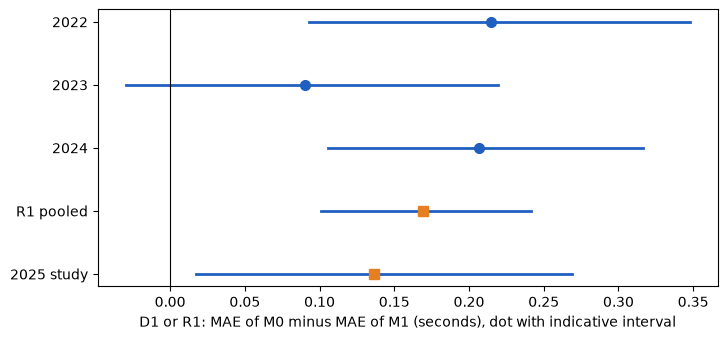

In [2]:
out = []
for y in xc.REPLICATION_SEASONS:
    s = pd.read_csv(rep / f"{y}_summary.csv").set_index("metric")["value"]
    out.append({"season": y, "D1": s["D1"], "D1_lo": s["D1_lo"], "D1_hi": s["D1_hi"], "D2": s["D2"], "D2_lo": s["D2_lo"], "D2_hi": s["D2_hi"],
                "races_M1_beat_M0": int(s["races_M1_beat_M0"]), "eligible": int(s["validation_eligible_races"])})
t = pd.DataFrame(out)
print(t.round(4).to_string(index=False))
print()
for k in ["R1", "R1_lo", "R1_hi", "R2", "R2_lo", "R2_hi", "races_pooled", "races_M1_beat_M0", "races_M2_beat_M1"]:
    print(k, round(float(pool[k]), 4))
for m in F.MODELS:
    print("pooled test MAE", m, round(float(pool[f"pooled_test_MAE_{m}"]), 4))
print()
for k in ["ALL4_D1", "ALL4_D1_lo", "ALL4_D1_hi", "ALL4_D2", "ALL4_races"]:
    print(k, round(float(pool[k]), 4), "(original plus replication, shown for reference)")
s25 = pd.read_csv("results/summary.csv").set_index("metric")["value"]
fig, ax = plt.subplots(figsize=(8, 3.6))
labels = [str(y) for y in xc.REPLICATION_SEASONS] + ["R1 pooled", "2025 study"]
vals = list(t["D1"]) + [pool["R1"], s25["D1"]]
los = list(t["D1_lo"]) + [pool["R1_lo"], s25["D1_lo"]]
his = list(t["D1_hi"]) + [pool["R1_hi"], s25["D1_hi"]]
for i, (l, v, a, b) in enumerate(zip(labels, vals, los, his)):
    ax.plot([a, b], [i, i], color="#1f5fbf", lw=2)
    ax.plot(v, i, "o" if i < 3 else "s", color="#e67e22" if i >= 3 else "#1f5fbf", ms=7)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlabel("D1 or R1: MAE of M0 minus MAE of M1 (seconds), dot with indicative interval")
fig.savefig("Images/replication_d1.png", dpi=150, bbox_inches="tight")
plt.show()

## Verdict
This sentence was chosen by the R1 interval, by the rule written before the data was downloaded.

In [3]:
print(Path("results/replication/verdict.txt").read_text().strip())

The replication interval for R1 is above zero: the 2025 result held in 2022 to 2024.


## Sensitivity tables
These are checks on the fixed design, not a search for a better setting.

In [4]:
for y in xc.REPLICATION_SEASONS:
    print(y, "train fraction")
    print(pd.read_csv(rep / f"{y}_sensitivity_train_fraction.csv").round(4).to_string(index=False))
    print(y, "clean air")
    print(pd.read_csv(rep / f"{y}_sensitivity_clean_air.csv").round(4).to_string(index=False))
    print()

2022 train fraction
 train_fraction  n_eligible     D1  D1_lo  D1_hi      D2   D2_lo   D2_hi
            0.5          18 0.1732 0.0515 0.3061 -0.0940 -0.2618  0.0075
            0.6          18 0.2145 0.0928 0.3476 -0.1307 -0.3285 -0.0131
            0.7          17 0.1217 0.0164 0.2171 -0.0956 -0.2442 -0.0076
2022 clean air
 train_fraction  n_eligible     D1  D1_lo  D1_hi     D2   D2_lo  D2_hi
            0.6          11 0.3494 0.1604 0.5466 -0.003 -0.0264 0.0196

2023 train fraction
 train_fraction  n_eligible     D1   D1_lo  D1_hi      D2   D2_lo   D2_hi
            0.5          20 0.1471 -0.0525 0.3893 -0.1470 -0.3175 -0.0292
            0.6          20 0.0902 -0.0296 0.2194 -0.0975 -0.2010 -0.0243
            0.7          20 0.0711 -0.0158 0.1589 -0.0621 -0.1099 -0.0264
2023 clean air
 train_fraction  n_eligible    D1  D1_lo  D1_hi      D2   D2_lo  D2_hi
            0.6          12 0.233 0.1282 0.3561 -0.0173 -0.0434 0.0062

2024 train fraction
 train_fraction  n_eligible     D1  

## What this shows and what it does not
The pre-registered replication interval for R1 is above zero, and the verdict sentence above comes straight from that rule. In each of 2022, 2023 and 2024 the mean D1 is positive, and the interval for 2023 includes zero on its own. The linear degradation term beat the model without it in most pooled races. The quadratic term made the forecast worse again: the interval for R2 is below zero and the pooled test MAE of M2 is above that of M1.

This does not show that the fitted rates are physical tyre wear. The replication seasons share the model, the filters and the lap-number term with 2025, so a flaw shared by all of them would replicate too. Compounds are different physical tyres in different seasons. About 20 races per season is a small sample, and the intervals come from resampling races, so they are indicative.